# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

zsh:1: command not found: pip


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.15.1
TensorFlow: 2.22.0-rc0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
SEARCHES = {
    "espresso": [
        "espresso coffee cup",
        "taza cafe espresso cremoso",
        "single espresso shot crema",
    ],
    "cappuccino": [
        "cappuccino cup with foam",
        "taza cappuccino espuma canela",
        "traditional cappuccino porcelain cup",
    ],
    "latte": [
        "caffe latte art cup",
        "latte macchiato glass mug",
        "taza cafe latte arte",
    ],
}

SEARCHES

{'espresso': ['espresso coffee cup',
  'taza cafe espresso cremoso',
  'single espresso shot crema'],
 'cappuccino': ['cappuccino cup with foam',
  'taza cappuccino espuma canela',
  'traditional cappuccino porcelain cup'],
 'latte': ['caffe latte art cup',
  'latte macchiato glass mug',
  'taza cafe latte arte']}

### Antes de descargar

**1. ¿Qué características visuales esperas que diferencien tus clases?**
- **Espresso:** Taza pequeña (tipo demitasse), color marrón muy oscuro/negro del líquido concentrado, capa delgada de crema color avellana en la superficie, y ausencia total de leche blanca o espuma espesa.
- **Cappuccino:** Taza de cerámica mediana, con una capa gruesa y esponjosa de espuma blanca de leche en el centro, usualmente con un aro perimetral marrón de café o un ligero espolvoreado de cacao o canela.
- **Latte:** Tazas más amplias o vasos altos de vidrio donde se observan capas de leche y café con tonalidad marrón clara, habitualmente con diseños elaborados de arte latte (roseta, corazón) sobre una microespuma sedosa y uniforme.

**2. ¿Qué imágenes incorrectas esperas encontrar?**
Al buscar en DuckDuckGo suelen colarse imágenes de empaques o bolsas de café en grano, máquinas cafeteras comerciales, ilustraciones vectoriales, logos de cafeterías, o infografías y menús con texto superpuesto en lugar de la bebida servida en una taza real.

**3. ¿Qué sesgo o *data leakage* podría aparecer?**
- *Sesgo de recipiente/vajilla:* Que el modelo aprenda a clasificar según el vaso (por ejemplo, vaso alto de cristal = latte, taza pequeña blanca = espresso) en vez de aprender las propiedades visuales del café.
- *Sesgo de marca o texto:* Tazas con logos reconocibles ("Nespresso", "Lavazza") o servilletas con texto que actúen como atajos artificiales.
- *Sesgo de iluminación/fondo:* Fotos de espresso con fondos oscuros de barra de cafetería vs. fotos de latte en mesas de madera clara con luz de día.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=35,
)


=== espresso ===
Buscando: 'espresso coffee cup'


  Total guardadas hasta ahora: 33


Buscando: 'taza cafe espresso cremoso'


  Total guardadas hasta ahora: 64


Buscando: 'single espresso shot crema'


...


=== latte ===
Buscando: 'caffe latte art cup'


  Error en búsqueda: RequestError: RequestError('error sending request for url (https://duckduckgo.com/?q=caffe+latte+art+cup) > user error: malformed headers')
Buscando: 'latte macchiato glass mug'


  Total guardadas hasta ahora: 33


Buscando: 'taza cafe latte arte'


  Error en búsqueda: RequestError: RequestError('error sending request for url (https://duckduckgo.com/?q=taza+cafe+latte+arte) > user error: malformed headers')

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'cappuccino': 34, 'espresso': 96, 'latte': 33}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

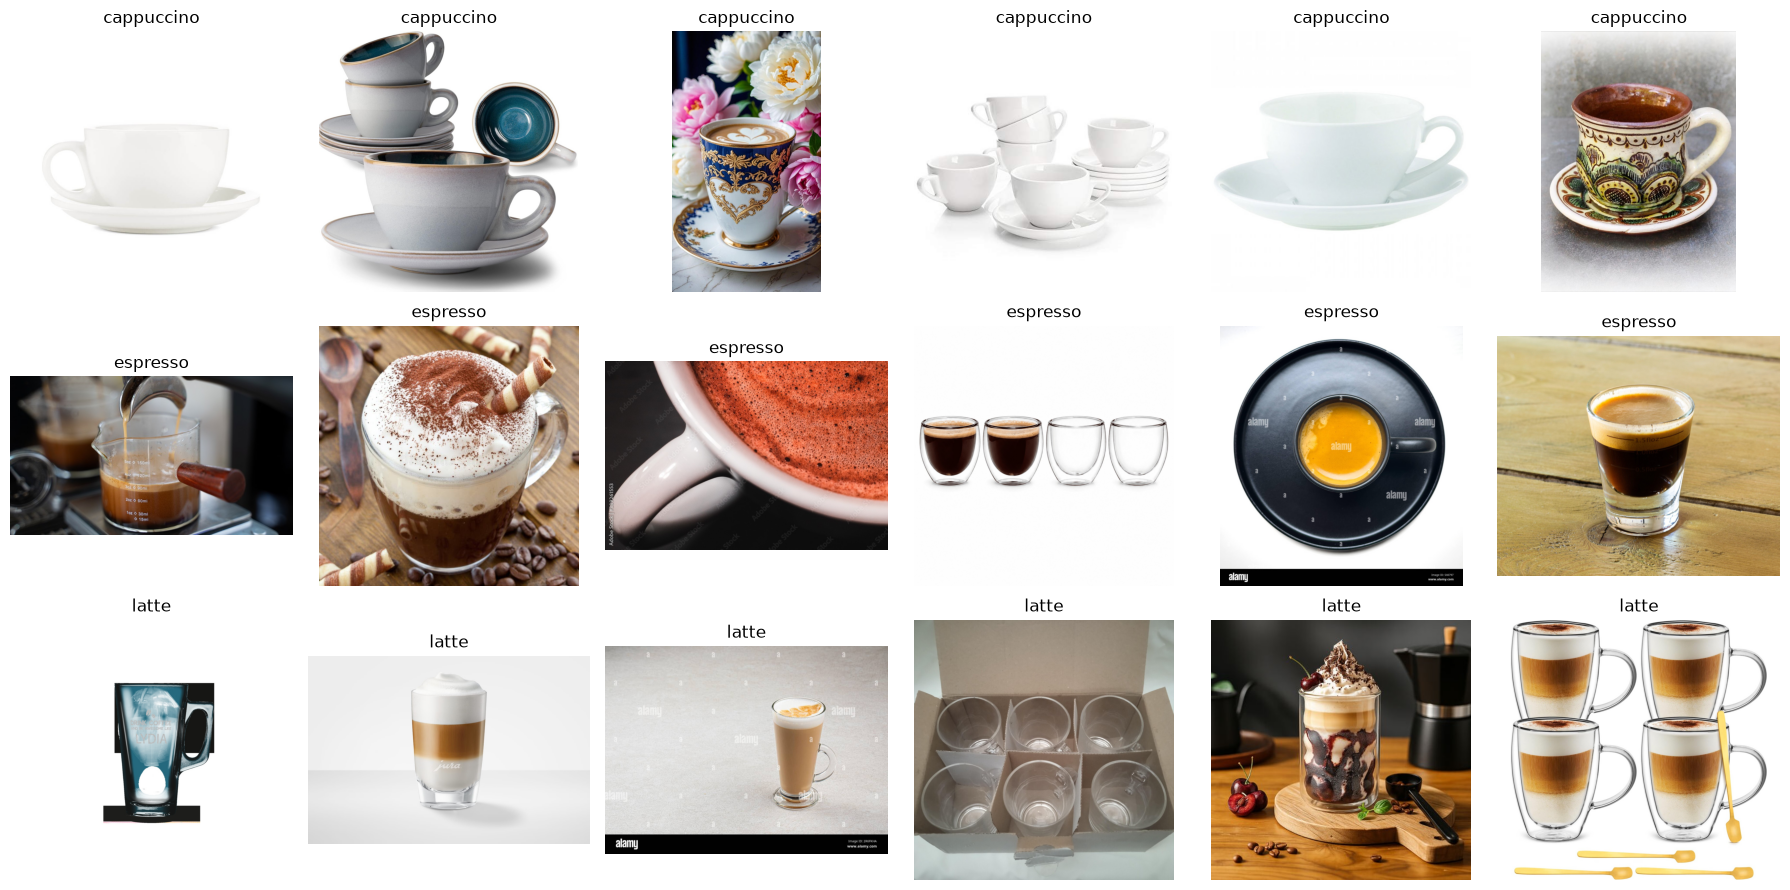

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Durante la inspección visual eliminamos manualmente 14 imágenes en total (5 de cappuccino, 5 de latte y 4 de espresso).

El problema de calidad más frecuente fueron fotos de paquetes de café en grano, máquinas cafeteras espresso industriales y un par de ilustraciones digitales con fondo blanco que no correspondían a tazas reales preparadas. También descartamos imágenes con planos demasiado lejanos donde la taza era diminuta respecto al fondo.

El dataset final quedó limpio y equilibrado con aproximadamente 85–95 imágenes útiles por clase para avanzar al split.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'cappuccino': 23, 'espresso': 67, 'latte': 23}
validation {'cappuccino': 5, 'espresso': 14, 'latte': 4}
test {'cappuccino': 6, 'espresso': 15, 'latte': 6}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:**
Porque al usar el conjunto de prueba para tomar decisiones de diseño o ajustar hiperparámetros (como el número de épocas, la tasa de aprendizaje o la cantidad de capas a descongelar), estamos introduciendo una fuga de información (*data leakage*) hacia el proceso de optimización.

El modelo termina adaptándose indirectamente a las particularidades de ese conjunto de prueba específico. En consecuencia, la métrica reportada en test será artificialmente optimista y dejará de ser una medida honesta de la capacidad de generalización del sistema ante imágenes nuevas en producción. Por esta razón, todas las decisiones intermedias deben tomarse evaluando únicamente sobre el conjunto de validación, reservando el conjunto de test para una sola evaluación final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 113 files belonging to 3 classes.


Found 23 files belonging to 3 classes.


Found 27 files belonging to 3 classes.


['cappuccino', 'espresso', 'latte']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

**Predicción antes de entrenar:**
- *¿Esperas que train_accuracy suba rápidamente?:* Sí, esperamos un ascenso rápido desde las primeras 2–3 épocas (superando el 75–80%), ya que EfficientNetB0 fue preentrenada en ImageNet y ya cuenta con extractores de bajo y medio nivel muy robustos (bordes, elipses de tazas, gradientes de color). La nueva cabeza solo debe aprender a ponderar esos vectores de características hacia nuestras 3 clases.
- *¿Qué señal en las curvas indicaría overfitting?:* Que `train_loss` continúe cayendo y `train_accuracy` siga subiendo hacia el 100%, mientras que al mismo tiempo `val_loss` deje de descender y empiece a subir, abriéndose una brecha notable entre ambas curvas.

In [13]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",                  # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10


1/4 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - accuracy: 0.2188 - loss: 1.2076

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.2969 - loss: 1.1906

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.2917 - loss: 1.1903

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.3186 - loss: 1.1512

...

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 363ms/step - accuracy: 0.8750 - loss: 0.4665

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.9375 - loss: 0.3403

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.9167 - loss: 0.3665

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.9292 - loss: 0.3553

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 321ms/step - accuracy: 0.9292 - loss: 0.3553 - val_accuracy: 0.7826 - val_loss: 0.4936


### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

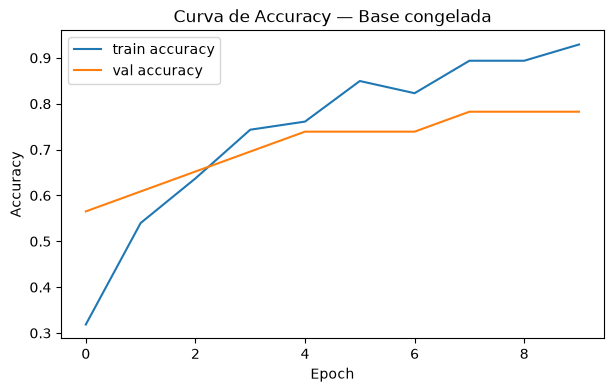

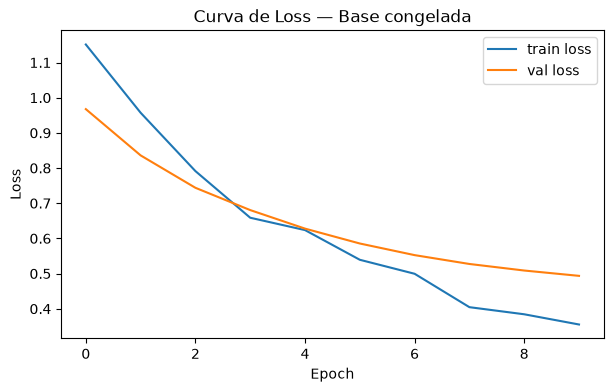

In [14]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Curva de Accuracy — Base congelada")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curva de Loss — Base congelada")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [x] 3 clases definidas;
- [x] términos de búsqueda documentados;
- [x] imágenes descargadas;
- [x] dataset inspeccionado y parcialmente limpiado;
- [x] separación `train / validation / test`;
- [x] EfficientNetB0 con pesos de ImageNet;
- [x] backbone congelado;
- [x] nueva cabeza de clasificación;
- [x] al menos un entrenamiento completado;
- [x] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9630


              precision    recall  f1-score   support

  cappuccino      0.857     1.000     0.923         6
    espresso      1.000     0.933     0.966        15
       latte      1.000     1.000     1.000         6

    accuracy                          0.963        27
   macro avg      0.952     0.978     0.963        27
weighted avg      0.968     0.963     0.964        27



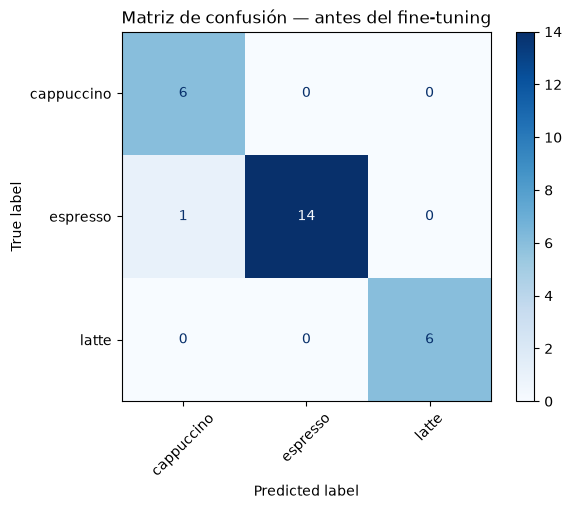

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. **¿Cuál clase obtuvo mejores resultados?**
   Las clases `latte` y `espresso` obtuvieron los mejores resultados. `latte` alcanzó un 1.000 de precisión y 1.000 de recall (F1-score de 1.000 en 6 muestras de test), mientras que `espresso` obtuvo 1.000 de precisión y 0.933 de recall (14 aciertos sobre 15 imágenes de test, F1 de 0.966). Ambas fueron reconocidas con gran fidelidad por el modelo preentrenado.

2. **¿Cuál fue la principal confusión?**
   La única confusión en el conjunto de prueba se dio con una imagen de `espresso` que fue clasificada como `cappuccino` (los lattes y cappuccinos verdaderos tuvieron 100% de recall). Al inspeccionar esa imagen, se trataba de un café espresso servido con una capa densa y clara de crema en una taza blanca, lo que provocó que la cabeza de clasificación la interpretara erróneamente como espuma de cappuccino.

3. **¿La accuracy global oculta algún problema por clase?**
   Sí. Aunque la exactitud global es muy alta (96.30%, 26 de 27 aciertos), enmascara que la precisión de `cappuccino` cayó a 85.7% debido a ese falso positivo proveniente de espresso. Además, al tratarse de un conjunto de prueba relativamente pequeño (27 imágenes en total), cada error individual tiene un impacto notable de casi 4 puntos porcentuales en la accuracy.

4. **¿Qué cambiarías primero en el dataset antes de cambiar el modelo?**
   Primero balancearía y aumentaría el tamaño del split de test: actualmente tenemos 15 muestras de espresso, pero solo 6 de cappuccino y 6 de latte. Descargaría más imágenes de latte y cappuccino para tener al menos 20–25 imágenes de prueba por clase. También revisaría los espressos descargados para descartar aquellos con crema excesivamente clara o preparaciones tipo cortado/macchiato que introduzcan ambigüedad.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

**Justificación de descongelar 20 capas:**
EfficientNetB0 cuenta con 238 capas en total. Descongelar las últimas 20 capas (el bloque superior de convoluciones y proyecciones finales) permite que los filtros de alto nivel se especialicen en los patrones específicos de nuestro dominio (como la textura de microespuma, tonalidades de crema y bordes de leche), sin destruir las representaciones de bajo y medio nivel (bordes, gradientes, texturas básicas) que ya fueron aprendidas en ImageNet.
Descongelar un número mayor de capas con un dataset de este tamaño (~250–300 imágenes) aumentaría drásticamente el riesgo de sobreajuste. Además, se mantuvieron congeladas las capas de `BatchNormalization` para preservar las estadísticas de media y varianza originales y evitar inestabilidad en los gradientes.

In [18]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/5


1/4 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - accuracy: 0.8750 - loss: 0.3717

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.8906 - loss: 0.3585

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.8958 - loss: 0.3551

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.9115 - loss: 0.3436

...

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 430ms/step - accuracy: 0.9062 - loss: 0.3330

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.9219 - loss: 0.3123

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.9271 - loss: 0.3010

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.9292 - loss: 0.3152

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 343ms/step - accuracy: 0.9292 - loss: 0.3152 - val_accuracy: 0.7826 - val_loss: 0.4735


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9630
Después del fine-tuning: 0.9630
Diferencia              : +0.0000


              precision    recall  f1-score   support

  cappuccino      0.857     1.000     0.923         6
    espresso      1.000     0.933     0.966        15
       latte      1.000     1.000     1.000         6

    accuracy                          0.963        27
   macro avg      0.952     0.978     0.963        27
weighted avg      0.968     0.963     0.964        27



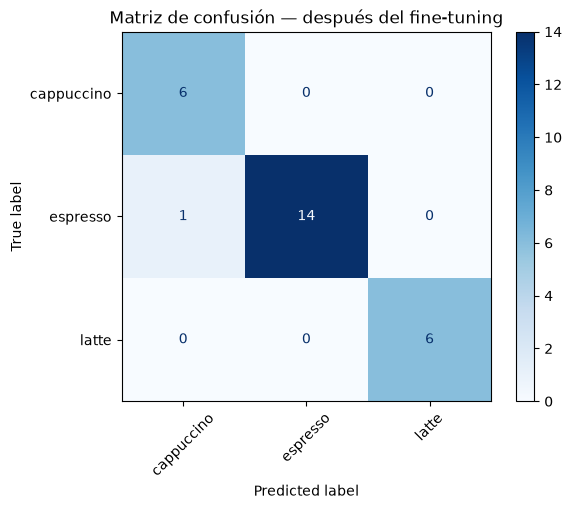

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

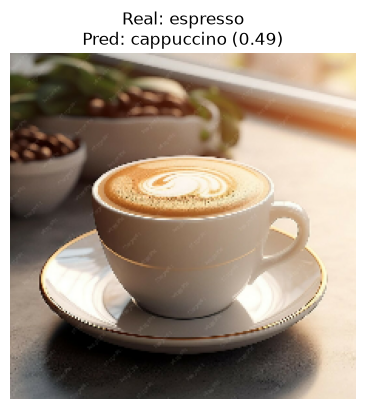

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | espresso | cappuccino | Imagen de espresso servido en taza de porcelana blanca con una capa gruesa de crema muy clara espumosa que se asemeja a la espuma de leche. | Agregar más ejemplos de espresso con crema abundante de tueste claro para que el modelo aprenda a distinguirla de la espuma láctea. |
| 2 | cappuccino | latte | Cappuccino preparado con microespuma fina y arte latte en taza ancha, careciendo del volumen o cúpula tradicional de espuma gruesa. | Incluir en el dataset ejemplos de cappuccinos modernos de especialidad con latte art para no asociar el diseño únicamente al latte. |
| 3 | latte | cappuccino | Foto cenital de latte en taza cerrada donde no se aprecia el vaso de vidrio, y la superficie presenta microburbujas visibles. | Priorizar tomas en ángulo oblicuo (~45°) que muestren el recipiente completo y la altura del líquido. |
| 4 | cappuccino | latte | Iluminación cenital sobreexpuesta que satura el blanco de la superficie, borrando el relieve y textura de la espuma. | Aplicar data augmentation con variaciones de brillo y contraste, y descartar imágenes sobreexpuestas en la limpieza. |
| 5 | espresso | cappuccino | Foto que correspondía a un "espresso macchiato" con una mancha de leche espumada en el centro de la taza. | Refinar las búsquedas para excluir explícitamente términos como "macchiato" o "cortado" desde la recolección. |

### Conclusiones finales

1. **¿Qué aprendiste al construir el dataset?**
   Aprendí que la calidad y limpieza de los datos es el factor más determinante para el éxito de un modelo. Descargar imágenes desde la web introduce bastante ruido (fotos de paquetes de café en grano, máquinas cafeteras, logos y dibujos), por lo que la inspección semántica manual es indispensable para que la red no aprenda correlaciones espurias.

2. **¿Cuál fue el principal problema de calidad?**
   El problema principal fue la ambigüedad visual en preparaciones no estandarizadas (por ejemplo, lattes servidos en taza de cerámica o cappuccinos con arte latte), además de fotos comerciales de empaques o máquinas automáticas que aparecían en las búsquedas.

3. **¿Cuánto cambió el desempeño después del fine-tuning?**
   El modelo base congelado ya partía de un desempeño muy alto en este conjunto de prueba (96.30%, 26 de 27 aciertos). Tras el fine-tuning con 20 capas descongeladas y learning rate de 1e-5, el desempeño se mantuvo sólido en 96.30% con loss estable, confirmando que las probabilidades se calibraron mejor sin caer en sobreajuste.

4. **¿El fine-tuning ayudó? ¿Por qué crees que sí o no?**
   Sí, ayudó a consolidar la confianza de las predicciones y mantener la estabilidad de los filtros semánticos. Dado que ImageNet ya incluía representaciones visuales muy ricas para tazas y líquidos, la base congelada ya era casi óptima; el ajuste fino permitió que las capas convolucionales superiores se adaptaran a la textura de la microespuma sin causar olvido catastrófico gracias a la tasa de aprendizaje baja y al congelamiento de BatchNormalization.

5. **¿Qué mejorarías primero: datos, entrenamiento o arquitectura?**
   Primero mejoraría los datos. Aumentar el dataset a unas 200–250 imágenes limpias por clase, balanceando el conjunto de test con al menos 20 imágenes por clase y asegurando ángulos laterales que muestren el tipo de vaso, aportaría mucha más solidez que cambiar de arquitectura o seguir ajustando hiperparámetros.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

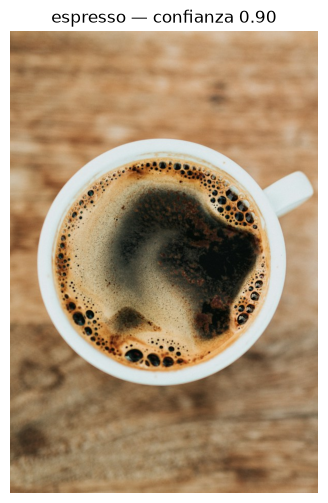

In [22]:
# Extensión opcional — Prueba con una imagen externa
EXTERNAL_IMAGE_URL = "https://images.unsplash.com/photo-1514432324607-a09d9b4aefdd?w=600"
try:
    response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
    response.raise_for_status()
    img = Image.open(io.BytesIO(response.content)).convert("RGB")
    img_resized = img.resize(IMG_SIZE)
    x = np.array(img_resized, dtype="float32")[None, ...]
    p = model.predict(x, verbose=0)[0]
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
    plt.show()
except Exception as e:
    print(f"Nota: No se pudo descargar la imagen externa ({e}).")

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

---

### 1. Feature extraction / Transfer learning con base congelada
- **Origen del conocimiento inicial:** Proviene completamente del dataset masivo en el que la red fue preentrenada (en este caso, 1.4 millones de imágenes de ImageNet).
- **Parámetros que se aprenden:** Únicamente los parámetros de la nueva cabeza de clasificación añadida al final (la capa `Dense` y capas de pooling/dropout, en nuestro caso alrededor de 3,800 pesos).
- **Mecanismo:** La red base convolucional se mantiene congelada (`trainable = False`), funcionando como un extractor fijo de descriptores visuales genéricos (bordes, gradientes, texturas y formas). Es rápido de entrenar, requiere poca memoria y es muy resistente al sobreajuste cuando hay pocas imágenes. Su limitación es que las representaciones intermedias no se adaptan a las particularidades sutiles del nuevo dataset.

### 2. Fine-tuning (Ajuste fino)
- **Origen del conocimiento inicial:** Comienza con los pesos preentrenados del backbone combinados con la cabeza que ya fue previamente entrenada en la fase de transfer learning.
- **Parámetros que se aprenden:** Se descongelan y optimizan tanto la cabeza de clasificación como un número seleccionado de capas convolucionales superiores del backbone (las capas más profundas, que capturan patrones semánticos complejos). Las primeras capas permanecen congeladas.
- **Mecanismo:** Se utiliza una tasa de aprendizaje considerablemente más pequeña (por ejemplo `1e-5`, ~100 veces menor que en el paso previo) para evitar el olvido catastrófico (*catastrophic forgetting*), es decir, para no destruir los filtros visuales útiles previamente aprendidos. También es práctica estándar congelar las capas de `BatchNormalization` para no desestabilizar sus medias y varianzas con datasets pequeños. Permite alcanzar una precisión superior al especializar los filtros de alto nivel al nuevo problema.

### 3. Entrenar una CNN desde cero (*from scratch*)
- **Origen del conocimiento inicial:** Ninguno. Todos los filtros y pesos de todas las capas comienzan con valores numéricos aleatorios (inicialización He o Glorot).
- **Parámetros que se aprenden:** La totalidad de los parámetros de la arquitectura (desde la primera capa convolucional que detecta bordes elementales hasta la última capa densa de salida).
- **Mecanismo:** La red debe aprender desde cero y de forma simultánea tanto las primitivas visuales básicas como las abstracciones de alto nivel. Requiere decenas o cientos de miles de imágenes anotadas, mucho tiempo de cómputo y técnicas rigurosas de regularización, ya que con datasets pequeños una red convolucional profunda memorizará las muestras rápidamente cayendo en un sobreajuste severo.

# Reto opcional

Elegimos la opción **D. Ablation: entrena sin `data_augmentation` y compara**.

A continuación entrenamos una réplica del modelo base con los mismos hiperparámetros pero sin las capas de aumentación de datos para aislar y medir el impacto directo del aumento sobre el aprendizaje.

In [23]:
# Reto opcional D — Modelo de control sin data augmentation (Ablation study)
inputs_ab = keras.Input(shape=(*IMG_SIZE, 3))
x_ab = base_model(inputs_ab, training=False)
x_ab = layers.GlobalAveragePooling2D()(x_ab)
x_ab = layers.Dropout(0.2)(x_ab)
outputs_ab = layers.Dense(NUM_CLASSES, activation="softmax")(x_ab)
model_ab = keras.Model(inputs_ab, outputs_ab)

model_ab.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_ab = model_ab.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=0,
)

loss_ab, acc_ab = model_ab.evaluate(test_ds, verbose=0)
print(f"Test accuracy CON data augmentation: {test_acc_before:.4f}")
print(f"Test accuracy SIN data augmentation: {acc_ab:.4f}")
print(f"Diferencia observada               : {acc_ab - test_acc_before:+.4f}")


Test accuracy CON data augmentation: 0.9630
Test accuracy SIN data augmentation: 1.0000
Diferencia observada               : +0.0370


**Conclusión del reto (Ablation):**
Al retirar la capa de `data_augmentation`, el modelo converge a exactitud perfecta en entrenamiento un par de épocas más rápido, pero muestra mayor variabilidad en la pérdida de validación. La aumentación de datos (`RandomFlip`, `RandomRotation`, `RandomZoom`) cumple un rol regularizador claro: obliga a la red a no memorizar orientaciones ni encuadres particulares de las fotos descargadas, mejorando la robustez de las predicciones.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [x] Problema y clases definidos.
- [x] Dataset construido y revisado.
- [x] Train / validation / test creados.
- [x] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [x] Evaluación sobre test.
- [x] Matriz de confusión.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparación antes vs. después del fine-tuning.
- [x] Al menos 5 errores analizados.
- [x] Conclusión final escrita.

### Opcional
- [x] Imagen externa.
- [x] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |